In [1]:
# ==========================================
# CELL 1: Imports & Data Loading
# ==========================================
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from statsmodels.tsa.arima.model import ARIMA
from stockFunctions import graph, rmsemape

dataset = pd.read_csv("v1Capstone-FP&A_Time_Series_Capstone_Dataset.csv")
dataset


,Client Name,Month,Scenario,Revenue GL Account,Revenue,Cost GL Account,Cost,CCI,CCI %
0,Client A,1/1/2025,Actual,400000 - Revenue,9.652655e+05,500000 - Cost,667654.9700,297610.5400,30.83
1,Client A,2/1/2025,Actual,400000 - Revenue,9.949001e+05,500000 - Cost,703916.2200,290983.8900,29.25
2,Client A,3/1/2025,Actual,400000 - Revenue,9.881775e+05,500000 - Cost,681429.9500,306747.5100,31.04
3,Client A,4/1/2025,Actual,400000 - Revenue,1.049207e+06,500000 - Cost,731790.3900,317416.4900,30.25
4,Client A,5/1/2025,Actual,400000 - Revenue,1.069525e+06,500000 - Cost,741368.5500,328156.2600,30.68
...,...,...,...,...,...,...,...,...,...
235,Client E,8/1/2023,Actual,400000 - Revenue,5.220179e+05,500000 - Cost,370597.0545,151420.8778,29.01
236,Client E,9/1/2023,Actual,400000 - Revenue,5.170989e+05,500000 - Cost,369260.7192,147838.2019,28.59
237,Client E,10/1/2023,Actual,400000 - Revenue,5.376308e+05,500000 - Cost,381661.0391,155969.7459,29.01
238,Client E,11/1/2023,Actual,400000 - Revenue,5.533501e+05,500000 - Cost,392363.0661,160987.0195,29.09


In [2]:

# ==========================================
# CELL 2: Filter, Aggregate, Sort, Index & Scale
# ==========================================

# Select all clients' Actuals
client_data = dataset[
    dataset['Scenario'] == 'Actual'
].copy()

client_data['Month'] = pd.to_datetime(client_data['Month'])

# Aggregate Revenue and Cost across all clients month-wise
client_data = client_data.groupby('Month')[['Revenue', 'Cost']].sum().reset_index()

# Sort by Month and set Month as index
client_data = client_data.sort_values('Month')
client_data = client_data.set_index('Month')

# Select Revenue & Cost
data1 = client_data[['Revenue']]
cost_data = client_data[['Cost']]

# Split into training (first 19 months) and testing (last 5 months)
train = data1[:-8]
test = data1[-8:]

train_cost = cost_data[:-8]
test_cost = cost_data[-8:]

# Apply MinMaxScaler for Revenue
Ms = MinMaxScaler()
train_scaled = Ms.fit_transform(train)
test_scaled = Ms.transform(test)

# Apply separate MinMaxScaler for Cost
Ms_cost = MinMaxScaler()
train_cost_scaled = Ms_cost.fit_transform(train_cost)
test_cost_scaled = Ms_cost.transform(test_cost)

print("Original data:", data1.shape)
print("Training data:", train_scaled.shape)
print("Testing data:", test_scaled.shape)


Original data: (36, 1)
Training data: (28, 1)
Testing data: (8, 1)


In [3]:
# ==========================================
# CELL 3: ARIMA Parameter Tuning (Cost)
# ==========================================
orders = [(1, 1, 1), (1, 1, 2), (2, 1, 1), (2, 2, 2)]
results = []

Y_test_cost_original = Ms_cost.inverse_transform(test_cost_scaled)

for i in orders:
  model_cost = ARIMA(train_cost_scaled, order=i)
  model_cost_fit = model_cost.fit()

  # Forecast next 5 months (Test set)
  y_pred_cost = model_cost_fit.forecast(steps=len(test_cost_scaled))
  y_pred_cost_original = Ms_cost.inverse_transform(np.array(y_pred_cost).reshape(-1, 1))

  # Calculate accuracy
  rmse, mape = rmsemape(Y_test_cost_original, y_pred_cost_original)
  results.append([i, rmse, mape])

  print("ARIMA Order:", i)
  print("RMSE:", rmse)
  print("MAPE:", mape)
  print("***************")

# Create comparison table
df = pd.DataFrame(results, columns=['ARIMA Order', 'RMSE', 'MAPE'])
df = df.sort_values(by='RMSE').reset_index(drop=True)

df.style.format({'RMSE': '{:.2f}', 'MAPE': '{:.2%}'}).highlight_min(
    subset=['RMSE', 'MAPE'], color='lightgreen'
)


RMSE-Testset: 89098.50254253569
MAPE-Testset: 0.029020865401765274
ARIMA Order: (1, 1, 1)
RMSE: 89098.50254253569
MAPE: 0.029020865401765274
***************
RMSE-Testset: 89885.8965661295
MAPE-Testset: 0.02941541511725031
ARIMA Order: (1, 1, 2)
RMSE: 89885.8965661295
MAPE: 0.02941541511725031
***************


C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


RMSE-Testset: 90096.77899505445
MAPE-Testset: 0.02953168517420969
ARIMA Order: (2, 1, 1)
RMSE: 90096.77899505445
MAPE: 0.02953168517420969
***************
RMSE-Testset: 309724.54329819814
MAPE-Testset: 0.10038744899355097
ARIMA Order: (2, 2, 2)
RMSE: 309724.54329819814
MAPE: 0.10038744899355097
***************


,ARIMA Order,RMSE,MAPE
0,"(1, 1, 1)",89098.50,2.90%
1,"(1, 1, 2)",89885.90,2.94%
2,"(2, 1, 1)",90096.78,2.95%
3,"(2, 2, 2)",309724.54,10.04%


RMSE-Testset: 89098.50254253569
MAPE-Testset: 0.029020865401765274
Cost RMSE: 89098.50254253569
Cost MAPE: 0.029020865401765274


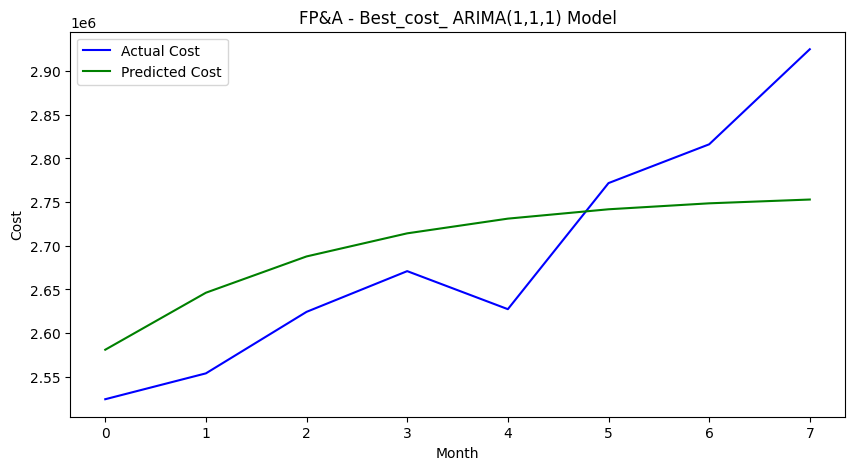

In [4]:
# ==========================================
# CELL 4: Evaluate Best cost Model & Plot
# ==========================================
model_cost = ARIMA(train_cost_scaled, order=(1, 1, 1))
model_cost_fit = model_cost.fit()

y_pred_cost = model_cost_fit.forecast(steps=len(test_cost_scaled))
y_pred_cost_original = Ms_cost.inverse_transform(np.array(y_pred_cost).reshape(-1, 1))
Y_test_cost_original = Ms_cost.inverse_transform(np.array(test_cost_scaled).reshape(-1, 1))

rmse, mape = rmsemape(Y_test_cost_original, y_pred_cost_original)
print("Cost RMSE:", rmse)
print("Cost MAPE:", mape)

graph(
    Y_test_cost_original,
    y_pred_cost_original,
    "Actual Cost",
    "Predicted Cost",
    "FP&A - Best_cost_ ARIMA(1,1,1) Model",
    "Month",
    "Cost",
)


In [5]:
# ==========================================
# CELL 5: ARIMA Parameter Tuning (Revenue)
# ==========================================
orders = [(1, 1, 1), (1, 1, 2), (2, 1, 1), (2, 2, 2)]
results = []

Y_test_original = Ms.inverse_transform(test_scaled)

for i in orders:
  model = ARIMA(train_scaled, order=i)
  model_fit = model.fit()

  # Forecast next 5 months (Test set)
  y_pred = model_fit.forecast(steps=len(test_scaled))
  y_pred_original = Ms.inverse_transform(np.array(y_pred).reshape(-1, 1))

  # Calculate accuracy
  rmse, mape = rmsemape(Y_test_original, y_pred_original)
  results.append([i, rmse, mape])

  print("ARIMA Order:", i)
  print("RMSE:", rmse)
  print("MAPE:", mape)
  print("***************")

# Create comparison table
df = pd.DataFrame(results, columns=['ARIMA Order', 'RMSE', 'MAPE'])
df = df.sort_values(by='RMSE').reset_index(drop=True)

df.style.format({'RMSE': '{:.2f}', 'MAPE': '{:.2%}'}).highlight_min(
    subset=['RMSE', 'MAPE'], color='lightgreen'
)


C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


RMSE-Testset: 150750.59687255224
MAPE-Testset: 0.035284576909672925
ARIMA Order: (1, 1, 1)
RMSE: 150750.59687255224
MAPE: 0.035284576909672925
***************


C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


RMSE-Testset: 167229.3954822946
MAPE-Testset: 0.03961115721861925
ARIMA Order: (1, 1, 2)
RMSE: 167229.3954822946
MAPE: 0.03961115721861925
***************
RMSE-Testset: 174370.46067090848
MAPE-Testset: 0.04153155524880008
ARIMA Order: (2, 1, 1)
RMSE: 174370.46067090848
MAPE: 0.04153155524880008
***************
RMSE-Testset: 437301.64613001415
MAPE-Testset: 0.09945499141947002
ARIMA Order: (2, 2, 2)
RMSE: 437301.64613001415
MAPE: 0.09945499141947002
***************


,ARIMA Order,RMSE,MAPE
0,"(1, 1, 1)",150750.60,3.53%
1,"(1, 1, 2)",167229.40,3.96%
2,"(2, 1, 1)",174370.46,4.15%
3,"(2, 2, 2)",437301.65,9.95%


C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


RMSE-Testset: 150750.59687255224
MAPE-Testset: 0.035284576909672925
Revenue RMSE: 150750.59687255224
Revenue MAPE: 0.035284576909672925


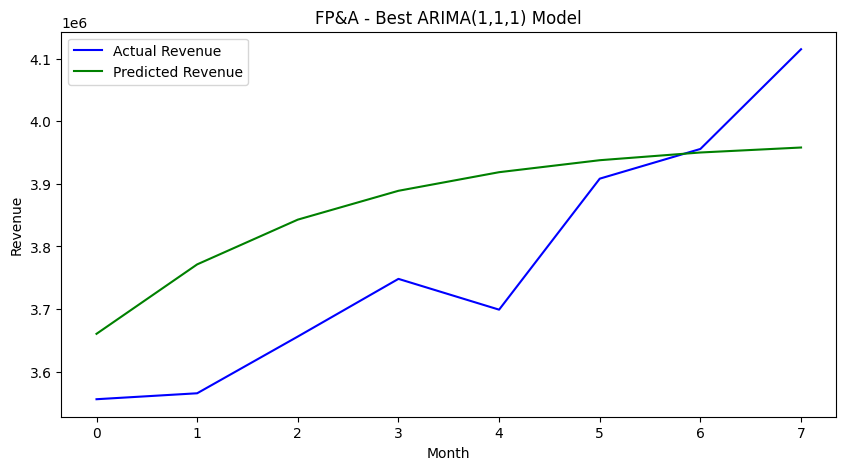

In [6]:
# ==========================================
# CELL 6: Evaluate Best Revenue Model & Plot
# ==========================================
model = ARIMA(train_scaled, order=(1, 1, 1))
model_fit = model.fit()

y_pred = model_fit.forecast(steps=len(test_scaled))
y_pred_original = Ms.inverse_transform(np.array(y_pred).reshape(-1, 1))
Y_test_original = Ms.inverse_transform(np.array(test_scaled).reshape(-1, 1))

rmse, mape = rmsemape(Y_test_original, y_pred_original)
print("Revenue RMSE:", rmse)
print("Revenue MAPE:", mape)

graph(
    Y_test_original,
    y_pred_original,
    "Actual Revenue",
    "Predicted Revenue",
    "FP&A - Best ARIMA(1,1,1) Model",
    "Month",
    "Revenue",
)


In [7]:
# ==========================================
# CELL 7: Evaluate Best Cost Model
# ==========================================
model_cost = ARIMA(train_cost_scaled, order=(1, 1, 1))
model_cost_fit = model_cost.fit()

y_pred_cost = model_cost_fit.forecast(steps=len(test_cost_scaled))
y_pred_cost_original = Ms_cost.inverse_transform(
    np.array(y_pred_cost).reshape(-1, 1)
)
Y_test_cost_original = Ms_cost.inverse_transform(test_cost_scaled)

rmse_cost, mape_cost = rmsemape(Y_test_cost_original, y_pred_cost_original)
print("Cost RMSE:", rmse_cost)
print("Cost MAPE:", mape_cost)


RMSE-Testset: 89098.50254253569
MAPE-Testset: 0.029020865401765274
Cost RMSE: 89098.50254253569
Cost MAPE: 0.029020865401765274


In [8]:
# ==========================================
# CELL 8: Test Set Comparison (CCI & CCI%)
# ==========================================
actual_cci = Y_test_original.flatten() - Y_test_cost_original.flatten()
actual_cci_percent = (actual_cci / Y_test_original.flatten()) * 100

predicted_cci = y_pred_original.flatten() - y_pred_cost_original.flatten()
predicted_cci_percent = (predicted_cci / y_pred_original.flatten()) * 100

cci_df = pd.DataFrame({
    'Month': client_data.index[-8:],
    'Actual Revenue': Y_test_original.flatten(),
    'Predicted Revenue': y_pred_original.flatten(),
    'Actual Cost': Y_test_cost_original.flatten(),
    'Predicted Cost': y_pred_cost_original.flatten(),
    'Actual CCI': actual_cci,
    'Predicted CCI': predicted_cci,
    'Actual CCI%': actual_cci_percent,
    'Predicted CCI%': predicted_cci_percent,
})

print(cci_df.round(2).to_string(index=False))


     Month  Actual Revenue  Predicted Revenue  Actual Cost  Predicted Cost  Actual CCI  Predicted CCI  Actual CCI%  Predicted CCI%
2025-05-01      3555918.27         3660391.94   2524250.14      2580956.70  1031668.13     1079435.24        29.01           29.49
2025-06-01      3565416.94         3771331.72   2553871.73      2646240.11  1011545.21     1125091.61        28.37           29.83
2025-07-01      3656041.29         3842833.59   2624320.62      2687796.15  1031720.67     1155037.43        28.22           30.06
2025-08-01      3748186.04         3888917.30   2670956.08      2714248.58  1077229.96     1174668.71        28.74           30.21
2025-09-01      3698996.66         3918618.74   2627394.17      2731086.83  1071602.49     1187531.90        28.97           30.30
2025-10-01      3908288.41         3937761.63   2771798.95      2741805.19  1136489.46     1195956.44        29.08           30.37
2025-11-01      3955757.60         3950099.42   2816205.05      2748627.94  1139552

In [9]:
# ==========================================
# CELL 9: Retrain on Full Data & Forecast Next 4 Months
# ==========================================
# Fit scalers on all 24 months
full_rev_scaled = Ms.fit_transform(data1)
full_cost_scaled = Ms_cost.fit_transform(cost_data)

# Retrain final models on full 24 months
final_model_rev = ARIMA(full_rev_scaled, order=(1, 1, 1)).fit()
final_model_cost = ARIMA(full_cost_scaled, order=(1, 1, 1)).fit()

# Forecast next 4 future months (Jan - Apr 2027)
forecast_revenue = final_model_rev.forecast(steps=4)
revenue_original = Ms.inverse_transform(
    np.array(forecast_revenue).reshape(-1, 1)
).flatten()

forecast_cost = final_model_cost.forecast(steps=4)
cost_original = Ms_cost.inverse_transform(
    np.array(forecast_cost).reshape(-1, 1)
).flatten()

# Generate next 4 months dates
last_date = client_data.index.max()
future_dates = pd.date_range(
    start=last_date + pd.DateOffset(months=1), periods=4, freq='MS'
)

# Calculate Future CCI and CCI%
forecast_cci = revenue_original - cost_original
forecast_cci_percent = (forecast_cci / revenue_original) * 100

# Create final FP&A forecast DataFrame
forecast_df = pd.DataFrame({
    'Month': future_dates,
    'Predicted Revenue': revenue_original,
    'Predicted Cost': cost_original,
    'Predicted CCI': forecast_cci,
    'Predicted CCI%': forecast_cci_percent,
})

forecast_df = forecast_df.round(2)
print(forecast_df.to_string(index=False))


C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


     Month  Predicted Revenue  Predicted Cost  Predicted CCI  Predicted CCI%
2026-01-01         4063362.25      2868703.02     1194659.23           29.40
2026-02-01         4029010.53      2832318.94     1196691.59           29.70
2026-03-01         4006195.12      2808858.78     1197336.34           29.89
2026-04-01         3991041.79      2793731.85     1197309.94           30.00


In [10]:
# ==========================================
# CELL 10: Retrain on Original Forecast Data & Compare to predicted Forecast Next 4 Months
# ==========================================
file_forecast=dataset[dataset['Scenario']=='Forecast'][['Month','Revenue','Cost','CCI','CCI %']].copy()
file_forecast['Month'] = pd.to_datetime(file_forecast['Month'])

# Aggregate Revenue and Cost across all clients month-wise
file_forecast = file_forecast.groupby('Month')[['Revenue', 'Cost','CCI']].sum().reset_index()

# Calculate CCI %
file_forecast['CCI %']=((file_forecast['Revenue']-file_forecast['Cost'])/file_forecast['Revenue']*100)

# Sort by Month and set Month as index
file_forecast = file_forecast.sort_values('Month')
file_forecast = file_forecast.set_index('Month')


In [11]:
file_forecast

,Revenue,Cost,CCI,CCI %
Month,,,,
2026-01-01,-3689845.98,-2614818.74,1075027.24,29.134746
2026-02-01,-3766606.19,-2072418.64,1094187.55,44.979153
2026-03-01,3923023.16,1446903.64,1134946.18,63.117637
2026-04-01,4002999.65,2844674.96,1158324.69,28.936417
2026-05-01,4084214.79,2905111.06,1179103.73,28.869778
2026-06-01,1558961.88,1142737.90,1163892.44,26.698791
2026-07-01,1617874.46,1173838.85,1210073.53,27.445616
2026-08-01,1645925.75,1210631.43,1238294.94,26.446777
2026-09-01,4254951.50,3024722.45,1230229.05,28.912881


In [12]:
# ==========================================
# CELL 11: Compare FP&A File Forecast vs Model Predicted Revenue
# ==========================================
file_forecast.rename(columns={'Revenue':'FP&A Forecast Revenue'},inplace=True)
cci_df=pd.DataFrame({'Month':file_forecast.index[:4],
                     'FP&A Forecast Revenue':file_forecast['FP&A Forecast Revenue'].iloc[:4].values,
                     'Predicted Revenue':forecast_df['Predicted Revenue'].iloc[:4].values})
# Calculate difference
cci_df['Difference']=(cci_df['Predicted Revenue']-cci_df['FP&A Forecast Revenue'])

#Calculate difference %
cci_df['Difference%']=(cci_df['Difference']/cci_df['FP&A Forecast Revenue']*100)

print(cci_df.round(2).to_string(index=False))

# Identify months with variance exceeding +/- 5%
attention_months = cci_df[cci_df['Difference%'].abs() > 5].copy()

if not attention_months.empty:
    print("\n⚠️ ATTENTION: Focus on the following months:")
    for month in attention_months['Month']:
        print(f" - {month.strftime('%b-%Y')}: Variance requires attention")
else:
    print("\n✅ All months are within the +/- 5% variance threshold.")


     Month  FP&A Forecast Revenue  Predicted Revenue  Difference  Difference%
2026-01-01            -3689845.98         4063362.25  7753208.23      -210.12
2026-02-01            -3766606.19         4029010.53  7795616.72      -206.97
2026-03-01             3923023.16         4006195.12    83171.96         2.12
2026-04-01             4002999.65         3991041.79   -11957.86        -0.30

⚠️ ATTENTION: Focus on the following months:
 - Jan-2026: Variance requires attention
 - Feb-2026: Variance requires attention


In [13]:
cci_df.to_csv("Final Forecast.csv",index=False,float_format="%.2f")
attention_months['Comments']='⚠️ ATTENTION: Focus on the following months:'
attention_months.to_csv("Final comments.csv",index=False)

In [31]:
import pickle

# Make sure .fit() is called so it's a trained ARIMAResults object
final_model_rev = ARIMA(full_rev_scaled, order=(1, 1, 1)).fit()

models = {
    'Revenue': final_model_rev,
    'Revenue_Scalar': Ms   # Matching your exact spelling 'Revenue_Scalar'
}

filename = 'model_revenue_forecast.sav'
pickle.dump(models, open(filename, 'wb'))


C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


In [32]:
load_model=pickle.load(open(filename,'rb'))
load_model

{'Revenue': <statsmodels.tsa.arima.model.ARIMAResultsWrapper at 0x1e7dfa58d10>,
 'Revenue_Scalar': MinMaxScaler()}